In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv("data/train.csv")

# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display the first five rows
display(df.head())

Dataset shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [2]:
# Display information about the columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [3]:
# Count missing values in each column
missing_values = df.isnull().sum()

# Show the 15 columns with the most missing values
display(missing_values.sort_values(ascending=False).head(15))

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
GarageYrBlt       81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtCond          37
dtype: int64

In [4]:
# Summary of house sale prices
df["SalePrice"].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

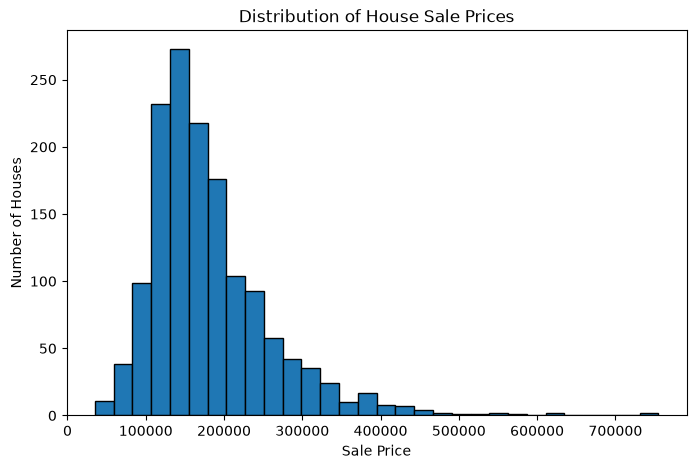

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df["SalePrice"], bins=30, edgecolor="black")

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Number of Houses")

plt.show()

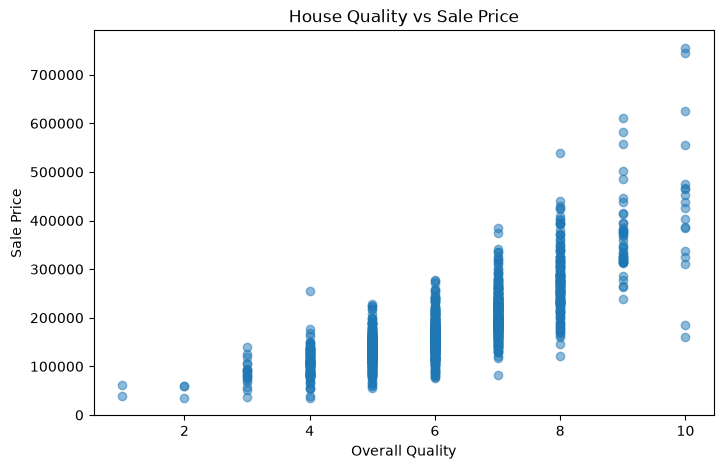

In [6]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["OverallQual"],
    df["SalePrice"],
    alpha=0.5
)

plt.title("House Quality vs Sale Price")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")

plt.show()

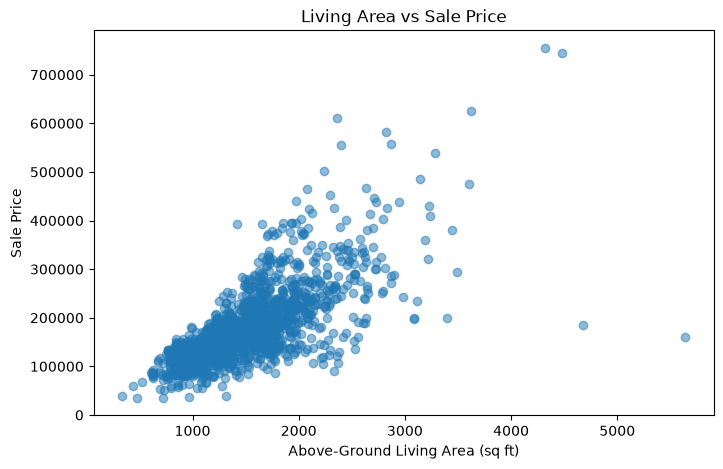

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["GrLivArea"],
    df["SalePrice"],
    alpha=0.5
)

plt.title("Living Area vs Sale Price")
plt.xlabel("Above-Ground Living Area (sq ft)")
plt.ylabel("Sale Price")

plt.show()

In [8]:
df.nlargest(10, "GrLivArea")[
    ["Id", "GrLivArea", "OverallQual", "YearBuilt", "GarageCars", "SalePrice"]
]

,Id,GrLivArea,OverallQual,YearBuilt,GarageCars,SalePrice
1298,1299,5642,10,2008,2,160000
523,524,4676,10,2007,3,184750
1182,1183,4476,10,1996,3,745000
691,692,4316,10,1994,3,755000
1169,1170,3627,10,1995,3,625000
185,186,3608,10,1892,3,475000
304,305,3493,7,1880,3,295000
1268,1269,3447,8,1935,3,381000
635,636,3395,6,1914,0,200000
769,770,3279,8,2003,3,538000


In [9]:
# Inspect houses with more than 4,000 sq ft of living area
large_houses = df.loc[
    df["GrLivArea"] > 4000,
    [
        "Id",
        "GrLivArea",
        "OverallQual",
        "YearBuilt",
        "YearRemodAdd",
        "Neighborhood",
        "TotRmsAbvGrd",
        "GarageCars",
        "SaleCondition",
        "SalePrice"
    ]
]

display(large_houses.sort_values("GrLivArea", ascending=False))

,Id,GrLivArea,OverallQual,YearBuilt,YearRemodAdd,Neighborhood,TotRmsAbvGrd,GarageCars,SaleCondition,SalePrice
1298,1299,5642,10,2008,2008,Edwards,12,2,Partial,160000
523,524,4676,10,2007,2008,Edwards,11,3,Partial,184750
1182,1183,4476,10,1996,1996,NoRidge,10,3,Abnorml,745000
691,692,4316,10,1994,1995,NoRidge,10,3,Normal,755000


In [10]:
# Keep the original dataset unchanged
df_model = df.copy()

# Identify unusually large houses with unusually low sale prices
outlier_mask = (
    (df_model["GrLivArea"] > 4000) &
    (df_model["SalePrice"] < 300000)
)

# Remove these records from the working dataset
df_model = df_model.loc[~outlier_mask].copy()

# Check the new dataset size
print("Original dataset:", df.shape)
print("Working dataset:", df_model.shape)
print("Records removed:", outlier_mask.sum())

Original dataset: (1460, 81)
Working dataset: (1458, 81)
Records removed: 2


In [11]:
# The target: what we want to predict
y = df_model["SalePrice"]

# The features: information used for prediction
# For our first model, we'll use numerical features only
X = df_model.drop(columns=["SalePrice", "Id"]).select_dtypes(
    include="number"
)

# Check the results
print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Features shape: (1458, 36)
Target shape: (1458,)


,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold
0,60,65.0,8450,7,5,2003,2003,196.0,706,0,...,548,0,61,0,0,0,0,0,2,2008
1,20,80.0,9600,6,8,1976,1976,0.0,978,0,...,460,298,0,0,0,0,0,0,5,2007
2,60,68.0,11250,7,5,2001,2002,162.0,486,0,...,608,0,42,0,0,0,0,0,9,2008
3,70,60.0,9550,7,5,1915,1970,0.0,216,0,...,642,0,35,272,0,0,0,0,2,2006
4,60,84.0,14260,8,5,2000,2000,350.0,655,0,...,836,192,84,0,0,0,0,0,12,2008


0    208500
1    181500
2    223500
3    140000
4    250000
Name: SalePrice, dtype: int64

In [12]:
from sklearn.model_selection import train_test_split

# Split features and target into training and validation sets
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Check the results
print("Training features:", X_train.shape)
print("Validation features:", X_valid.shape)
print("Training target:", y_train.shape)
print("Validation target:", y_valid.shape)

Training features: (1166, 36)
Validation features: (292, 36)
Training target: (1166,)
Validation target: (292,)


In [13]:
# Count missing values in each training feature
missing_counts = X_train.isnull().sum()

# Display only columns that contain missing values
display(
    missing_counts[missing_counts > 0]
    .sort_values(ascending=False)
)

LotFrontage    213
GarageYrBlt     68
MasVnrArea       6
dtype: int64

In [14]:
from sklearn.impute import SimpleImputer
import pandas as pd

# Create the imputer
imputer = SimpleImputer(strategy="median")

# Learn medians from training data and fill missing values
X_train_clean = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Apply the same medians to validation data
X_valid_clean = pd.DataFrame(
    imputer.transform(X_valid),
    columns=X_valid.columns,
    index=X_valid.index
)

print("Missing values in training data:",
      X_train_clean.isnull().sum().sum())

print("Missing values in validation data:",
      X_valid_clean.isnull().sum().sum())

Missing values in training data: 0
Missing values in validation data: 0


In [15]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# Create our model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
model.fit(X_train_clean, y_train)

# Predict prices for houses the model hasn't seen
predictions = model.predict(X_valid_clean)

# Evaluate the predictions
mae = mean_absolute_error(y_valid, predictions)

print(f"Mean Absolute Error: ${mae:,.2f}")

Mean Absolute Error: $17,371.09


In [16]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error

# Create a simple baseline model
baseline_model = DummyRegressor(strategy="median")

# Train it using the training prices
baseline_model.fit(X_train_clean, y_train)

# Predict the validation prices
baseline_predictions = baseline_model.predict(X_valid_clean)

# Calculate its error
baseline_mae = mean_absolute_error(
    y_valid,
    baseline_predictions
)

# Compare both models
print(f"Baseline MAE:      ${baseline_mae:,.2f}")
print(f"Random Forest MAE: ${mae:,.2f}")

Baseline MAE:      $57,100.22
Random Forest MAE: $17,371.09


In [20]:
# Compare actual and predicted prices
results = pd.DataFrame({
    "Actual Price": y_valid,
    "Predicted Price": predictions
}, index=y_valid.index)

# Calculate the absolute error for each house
results["Absolute Error"] = (
    results["Actual Price"] - results["Predicted Price"]
).abs()

# Display 10 predictions
display(results.head(10).round(2))

,Actual Price,Predicted Price,Absolute Error
1322,190000,206424.18,16424.18
837,100000,93174.04,6825.96
413,115000,115157.30,157.30
522,159000,158517.95,482.05
1036,315500,297541.78,17958.22
615,137500,146213.60,8713.60
218,311500,218086.60,93413.40
1032,310000,312072.33,2072.33
1289,281000,268828.46,12171.54
887,135500,136555.87,1055.87


In [21]:
# Get the model's feature importance scores
importances = pd.Series(
    model.feature_importances_,
    index=X_train_clean.columns
).sort_values(ascending=False)

# Display the 15 most important features
display(importances.head(15))

OverallQual     0.562219
GrLivArea       0.122490
TotalBsmtSF     0.064571
BsmtFinSF1      0.030786
1stFlrSF        0.027657
GarageArea      0.022513
2ndFlrSF        0.022351
LotArea         0.016847
TotRmsAbvGrd    0.015155
YearBuilt       0.014491
FullBath        0.012244
MasVnrArea      0.010425
GarageCars      0.010084
YearRemodAdd    0.009643
LotFrontage     0.007612
dtype: float64

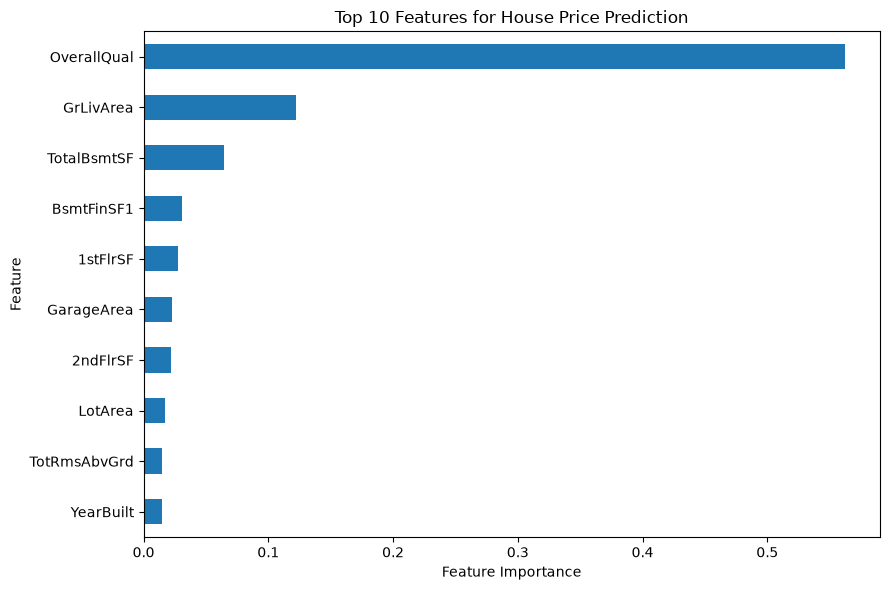

In [22]:
import matplotlib.pyplot as plt

top_features = importances.head(10).sort_values()

plt.figure(figsize=(9, 6))
top_features.plot(kind="barh")

plt.title("Top 10 Features for House Price Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [23]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import pandas as pd

settings = [
    {"max_depth": None, "min_samples_leaf": 1},
    {"max_depth": 10, "min_samples_leaf": 1},
    {"max_depth": 20, "min_samples_leaf": 1},
    {"max_depth": None, "min_samples_leaf": 2},
    {"max_depth": None, "min_samples_leaf": 4},
    {"max_depth": 15, "min_samples_leaf": 2}
]

results = []

for setting in settings:
    new_model = RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        **setting
    )

    new_model.fit(X_train_clean, y_train)
    new_predictions = new_model.predict(X_valid_clean)

    new_mae = mean_absolute_error(y_valid, new_predictions)

    results.append({
        "Max Depth": setting["max_depth"],
        "Min Samples Leaf": setting["min_samples_leaf"],
        "MAE": new_mae
    })

comparison = pd.DataFrame(results)
comparison = comparison.sort_values("MAE")

display(comparison.round(2))

,Max Depth,Min Samples Leaf,MAE
2,20.0,1,17369.08
0,NaN,1,17371.09
3,NaN,2,17400.43
5,15.0,2,17419.71
1,10.0,1,17444.47
4,NaN,4,17590.42


In [24]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# Separate features and target
X_all = df_model.drop(columns=["SalePrice", "Id"])
y_all = df_model["SalePrice"]

# Use the same 80/20 split for a fair comparison
X_train_all, X_valid_all, y_train_all, y_valid_all = train_test_split(
    X_all, y_all, test_size=0.2, random_state=42
)

# Identify numerical and categorical columns
numerical_features = X_train_all.select_dtypes(
    include="number"
).columns

categorical_features = X_train_all.select_dtypes(
    exclude="number"
).columns

# Fill missing numerical values with the median
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Fill missing categories, then encode them
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct preprocessing to each column type
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Build the complete model
categorical_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ))
])

# Train and evaluate
categorical_model.fit(X_train_all, y_train_all)

categorical_predictions = categorical_model.predict(X_valid_all)

categorical_mae = mean_absolute_error(
    y_valid_all, categorical_predictions
)

print(f"Numeric-only MAE:       ${mae:,.2f}")
print(f"All-features MAE:       ${categorical_mae:,.2f}")

Numeric-only MAE:       $17,371.09
All-features MAE:       $16,969.75


In [25]:
from sklearn.model_selection import cross_val_score
import numpy as np

cv_scores = cross_val_score(
    categorical_model,
    X_all,
    y_all,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=1
)

# Scikit-learn returns negative MAE for this scoring option.
cv_mae = -cv_scores

print("MAE for each fold:")
for i, score in enumerate(cv_mae, start=1):
    print(f"Fold {i}: ${score:,.2f}")

print(f"\nAverage CV MAE: ${np.mean(cv_mae):,.2f}")
print(f"Standard deviation: ${np.std(cv_mae):,.2f}")

MAE for each fold:
Fold 1: $17,207.50
Fold 2: $16,501.06
Fold 3: $17,721.11
Fold 4: $16,146.81
Fold 5: $18,087.12

Average CV MAE: $17,132.72
Standard deviation: $725.77


In [26]:
from sklearn.model_selection import cross_val_score, KFold
import numpy as np

# Create five shuffled folds
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the model again
cv_scores = cross_val_score(
    categorical_model,
    X_all,
    y_all,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=1
)

cv_mae = -cv_scores

for i, score in enumerate(cv_mae, start=1):
    print(f"Fold {i}: ${score:,.2f}")

print(f"\nAverage CV MAE: ${np.mean(cv_mae):,.2f}")
print(f"Standard deviation: ${np.std(cv_mae):,.2f}")

Fold 1: $17,278.25
Fold 2: $16,968.45
Fold 3: $18,283.24
Fold 4: $16,735.50
Fold 5: $16,994.36

Average CV MAE: $17,251.96
Standard deviation: $543.64


In [27]:
# Predict prices for the validation houses
categorical_predictions = categorical_model.predict(X_valid_all)

# Compare actual and predicted prices
error_analysis = pd.DataFrame({
    "Actual Price": y_valid_all,
    "Predicted Price": categorical_predictions
})

# Calculate absolute prediction errors
error_analysis["Absolute Error"] = (
    error_analysis["Actual Price"]
    - error_analysis["Predicted Price"]
).abs()

# Display the 10 largest errors
worst_predictions = error_analysis.sort_values(
    "Absolute Error",
    ascending=False
).head(10)

display(worst_predictions.round(2))

,Actual Price,Predicted Price,Absolute Error
1044,278000,373900.48,95900.48
218,311500,215717.57,95782.43
231,403000,316090.98,86909.02
1024,287000,369343.08,82343.08
666,129000,207020.83,78020.83
1310,335000,260918.81,74081.19
716,159500,230707.10,71207.10
196,311872,243088.53,68783.47
451,280000,214887.00,65113.00
426,275000,211402.42,63597.58


In [28]:
# Select useful features for the 10 houses with the largest errors
columns_to_check = [
    "Id",
    "SalePrice",
    "OverallQual",
    "GrLivArea",
    "TotalBsmtSF",
    "GarageCars",
    "YearBuilt",
    "YearRemodAdd",
    "Neighborhood",
    "HouseStyle",
    "SaleCondition"
]

house_details = df_model.loc[
    worst_predictions.index, columns_to_check
].copy()

# Add the model's predictions and errors
house_details["PredictedPrice"] = (
    worst_predictions["Predicted Price"]
)

house_details["AbsoluteError"] = (
    worst_predictions["Absolute Error"]
)

display(
    house_details
    .sort_values("AbsoluteError", ascending=False)
    .round(2)
)

,Id,SalePrice,OverallQual,GrLivArea,TotalBsmtSF,GarageCars,YearBuilt,YearRemodAdd,Neighborhood,HouseStyle,SaleCondition,PredictedPrice,AbsoluteError
1044,1045,278000,8,2524,2524,2,1981,1981,NWAmes,1Story,Normal,373900.48,95900.48
218,219,311500,7,1954,798,2,1939,2006,Crawfor,1.5Fin,Normal,215717.57,95782.43
231,232,403000,8,2794,1462,3,1995,1996,NoRidge,2Story,Normal,316090.98,86909.02
1024,1025,287000,8,2898,1565,2,1976,1976,Timber,1Story,Abnorml,369343.08,82343.08
666,667,129000,6,2380,1021,2,1965,1979,NAmes,2Story,Abnorml,207020.83,78020.83
1310,1311,335000,7,1902,1902,2,1959,2002,Crawfor,1Story,Normal,260918.81,74081.19
716,717,159500,7,2554,718,2,1890,1998,OldTown,2Story,Normal,230707.10,71207.10
196,197,311872,7,1726,1726,3,2007,2007,Somerst,1Story,Partial,243088.53,68783.47
451,452,280000,7,1533,1533,2,1975,1975,ClearCr,1Story,Normal,214887.00,65113.00
426,427,275000,7,1644,1518,2,1989,1989,SawyerW,SLvl,Normal,211402.42,63597.58


In [29]:
from sklearn.inspection import permutation_importance

importance_result = permutation_importance(
    categorical_model,
    X_valid_all,
    y_valid_all,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

feature_importance = pd.DataFrame({
    "Feature": X_valid_all.columns,
    "MAE Increase": importance_result.importances_mean
}).sort_values("MAE Increase", ascending=False)

display(feature_importance.head(15).round(2))

,Feature,MAE Increase
16,OverallQual,19680.44
45,GrLivArea,9936.39
37,TotalBsmtSF,2655.42
33,BsmtFinSF1,1345.61
61,GarageArea,1100.34
18,YearBuilt,755.72
3,LotArea,501.80
17,OverallCond,441.53
19,YearRemodAdd,389.00
60,GarageCars,340.29


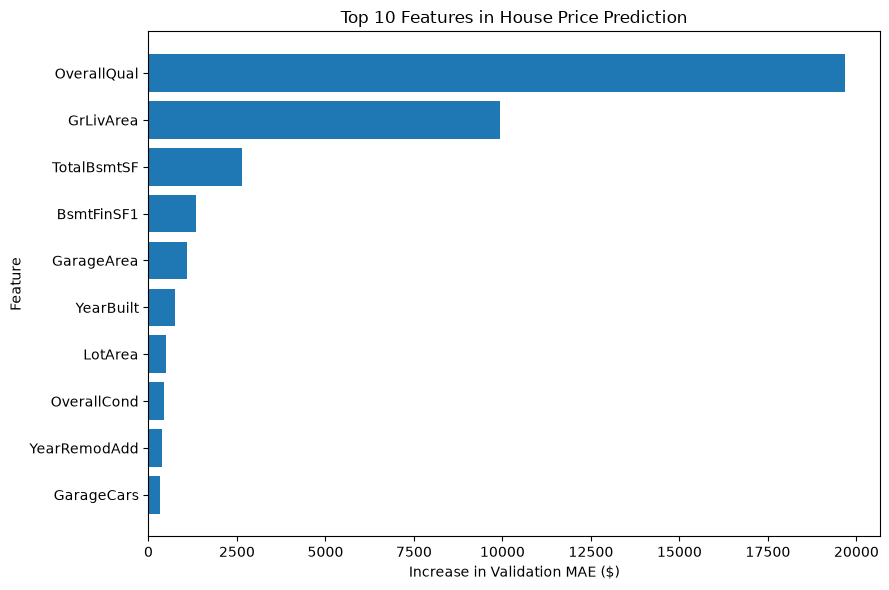

In [30]:
import matplotlib.pyplot as plt

top_features = (
    feature_importance
    .head(10)
    .sort_values("MAE Increase")
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"],
    top_features["MAE Increase"]
)

plt.title("Top 10 Features in House Price Prediction")
plt.xlabel("Increase in Validation MAE ($)")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [32]:
import matplotlib.pyplot as plt

top_features = (
    feature_importance
    .head(10)
    .sort_values("MAE Increase")
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"],
    top_features["MAE Increase"]
)

plt.title("Top 10 Features in House Price Prediction")
plt.xlabel("Increase in Validation MAE ($)")
plt.ylabel("Feature")

plt.tight_layout()

# Save the chart
plt.savefig(
    "top_10_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("Chart saved successfully!")

Chart saved successfully!
